In [13]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal

In [14]:
class QuadState(TypedDict):
    a : int
    b : int
    c : int
    
    equation : str
    discriminant : float
    
    result : str

In [15]:
def show_equation(state: QuadState):
    
    equation = f'{state['a']}x2 {state["b"]}x {state["c"]}'
    
    return {'equation':equation}

In [16]:
def cal_ditri(state:QuadState):
    discriminant = state['b']**2 - (4*state['a']*state['c'])
    
    return {'discriminant':discriminant}

In [17]:
def real_roots(state:QuadState):
    
    root1 = -state['b'] + ((state['discriminant']**0.5)/2*state['a'])
    root2 = -state['b'] - ((state['discriminant']**0.5)/2*state['a'])
    
    result =  f'The roots are {root1} and {root2}'
    
    return {'result':result}

def reapeted_root(state:QuadState):
    
    root = (-state['b'])/(2*state['a']) 
    
    
    result =  f'Only Reapeting Root is {root}'
    
    return {'result':result}

def No_real_roots(state:QuadState):
    
    result =  f'No real rooots.'
    
    return {'result':result}

In [18]:
def check_condition(state:QuadState) -> Literal['real_roots','reapeted_root','No_real_roots']:
    if state['discriminant'] > 0:
        return 'real_roots'
    elif(state['discriminant'] == 0):
        return 'real_roots'
    else:
        return 'No_real_roots'

In [19]:
graph = StateGraph(QuadState)

In [20]:
graph.add_node('show_equation',show_equation)
graph.add_node('cal_ditri',cal_ditri)
graph.add_node('real_roots',real_roots)
graph.add_node('reapeted_root',reapeted_root)
graph.add_node('No_real_roots',No_real_roots)

In [21]:
graph.add_edge(START,'show_equation')
graph.add_edge('show_equation','cal_ditri')
graph.add_conditional_edges('cal_ditri',check_condition)
graph.add_edge('real_roots',END)
graph.add_edge('reapeted_root',END)
graph.add_edge('No_real_roots',END)

workflow = graph.compile()

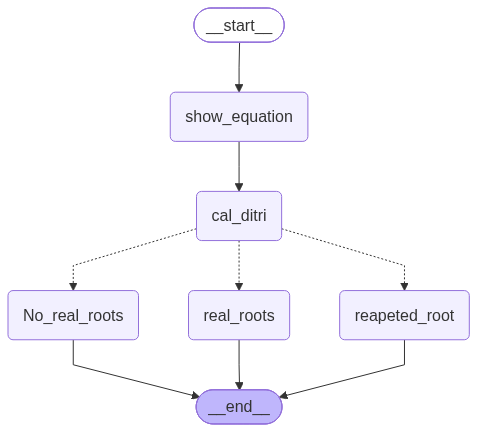

In [22]:
workflow

In [23]:
initial_state = {
    'a':4,
    'b':-5,
    'c':-4
}

workflow.invoke(initial_state)

{'a': 4,
 'b': -5,
 'c': -4,
 'equation': '4x2 -5x -4',
 'discriminant': 89,
 'result': 'The roots are 23.867962264113206 and -13.867962264113206'}